<a href="https://colab.research.google.com/github/Farrel45/JST/blob/main/JST_Kelompok3_MobileNetV2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pengenalan Gestur Tangan (Batu, Gunting, Kertas) Menggunakan CNN MobileNetV2

Tugas Jaringan Syaraf Tiruan, Kelompok 3, Teknik Fisika ITS

Data yang dipakai:
1. Rock Paper Scissors (Laurence Moroney) dari TensorFlow Datasets: 2520 gambar train dan 372 gambar test, render 3D berlatar putih
2. Rock Paper Scissors (Julien de la Bruere-Terreault) dari Kaggle: 2188 foto tangan asli berlatar hijau
3. HaGRID (Kapitanov dkk., 2022), versi sampel 30k: foto orang asli dengan wajah dan ruangan terlihat, diambil kelas fist, palm, peace
4. (opsional) frame dari video gestur tangan yang kami rekam sendiri

Jalankan di Google Colab. Sebaiknya pakai GPU (Runtime > Ubah jenis runtime > T4 GPU). CPU juga bisa, tapi lebih lama.

## 1. Import library dan load dataset

In [1]:
# tensorflow_datasets di Colab (Python 3.13) butuh paket ini
!pip install -q importlib_resources

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
import tensorflow_datasets as tfds
from PIL import Image, ImageOps
from tensorflow.keras import layers, models
from sklearn.metrics import confusion_matrix, classification_report

tf.random.set_seed(42)
np.random.seed(42)

# train dibagi 80% untuk training dan 20% untuk validasi
(train_ds, val_ds, test_ds), info = tfds.load(
    "rock_paper_scissors",
    split=["train[:80%]", "train[80%:]", "test"],
    as_supervised=True,
    with_info=True,
)

KELAS = ["batu", "kertas", "gunting"]   # urutan label di dataset: rock, paper, scissors
print(info.features["label"].names)
print("train:", len(train_ds), " val:", len(val_ds), " test:", len(test_ds))

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/2 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/rock_paper_scissors/incomplete.D2TSO7_3.0.0/rock_paper_scissors-train.tfre…

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/rock_paper_scissors/incomplete.D2TSO7_3.0.0/rock_paper_scissors-test.tfrec…

Dataset rock_paper_scissors downloaded and prepared to /root/tensorflow_datasets/rock_paper_scissors/3.0.0. Subsequent calls will reuse this data.
['rock', 'paper', 'scissors']
train: 2016  val: 504  test: 372


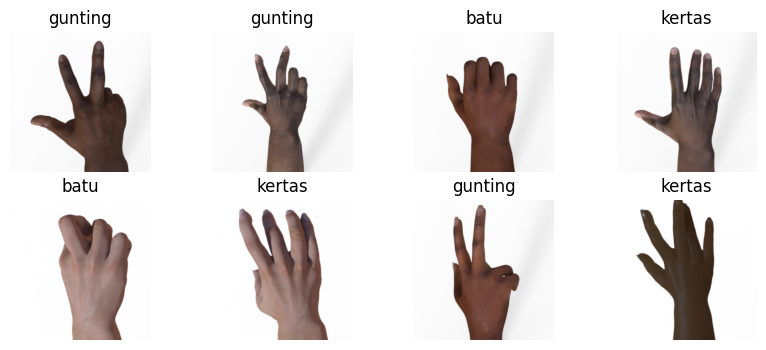

In [3]:
# lihat contoh gambar
plt.figure(figsize=(10, 4))
for i, (img, label) in enumerate(train_ds.take(8)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(img)
    plt.title(KELAS[label])
    plt.axis("off")
plt.show()

## 2. Dataset foto asli (Kaggle)

Dataset kedua berisi foto tangan asli (bukan render 3D) dengan background hijau, ukuran 300x200.
Foto dibuat persegi dengan menambah pinggiran hijau (padding), lalu diubah ke 160x160.
Dataset ini dibagi 70% train, 15% validasi, 15% test.

In [4]:
import kagglehub

try:
    path = kagglehub.dataset_download("drgfreeman/rockpaperscissors")
except Exception as e:
    print("Download gagal, login Kaggle dulu (Settings > API > Create New Token)")
    kagglehub.login()
    path = kagglehub.dataset_download("drgfreeman/rockpaperscissors")

# cari folder yang isinya rock, paper, scissors
for root, dirs, _ in os.walk(path):
    if {"rock", "paper", "scissors"} <= set(dirs):
        folder_kaggle = root
        break
print(folder_kaggle)

Using Colab cache for faster access to the 'rockpaperscissors' dataset.
/kaggle/input/rockpaperscissors


kaggle train: 1531  val: 328  test: 329


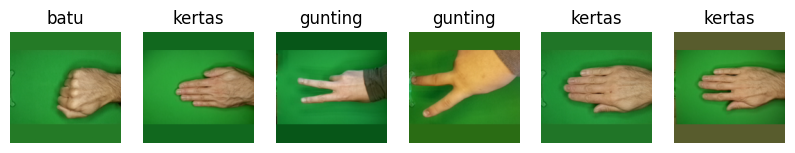

In [5]:
IMG_SIZE = 160   # ukuran input MobileNetV2

def load_kaggle(folder):
    X, y = [], []
    for label, nama in enumerate(["rock", "paper", "scissors"]):   # sama dengan urutan KELAS
        for f in sorted(os.listdir(os.path.join(folder, nama))):
            img = Image.open(os.path.join(folder, nama, f)).convert("RGB")
            warna_bg = img.getpixel((0, 0))                          # warna hijau di pojok
            img = ImageOps.pad(img, (IMG_SIZE, IMG_SIZE), color=warna_bg)
            X.append(np.array(img) / 255.0)
            y.append(label)
    return np.array(X, dtype=np.float32), np.array(y)

Xk, yk = load_kaggle(folder_kaggle)

idx = np.random.permutation(len(Xk))
n_train, n_val = int(0.70 * len(Xk)), int(0.15 * len(Xk))
i_train, i_val, i_test = idx[:n_train], idx[n_train:n_train + n_val], idx[n_train + n_val:]
Xk_train, yk_train = Xk[i_train], yk[i_train]
Xk_val, yk_val = Xk[i_val], yk[i_val]
Xk_test, yk_test = Xk[i_test], yk[i_test]
print("kaggle train:", len(Xk_train), " val:", len(Xk_val), " test:", len(Xk_test))

plt.figure(figsize=(10, 2.5))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    plt.imshow(Xk_train[i])
    plt.title(KELAS[yk_train[i]])
    plt.axis("off")
plt.show()

## 2b. Dataset HaGRID (foto orang dengan wajah dan ruangan)

Dataset RPS dan Kaggle hanya berisi tangan di background polos. Akibatnya model bingung kalau di foto ada wajah.
HaGRID berisi foto orang asli di dalam ruangan dengan wajah terlihat, jadi model belajar membedakan tangan dari wajah.

Kelas yang diambil: fist = batu, palm = kertas, peace = gunting (maksimal 1000 foto per kelas).
Tiap foto di-crop di sekitar tangan dengan ukuran acak (2 sampai 6 kali ukuran tangan),
jadi kadang tangannya besar, kadang kecil dengan wajah dan ruangan ikut kelihatan.

In [6]:
import json, glob, zipfile
from huggingface_hub import hf_hub_download

zip_hagrid = hf_hub_download("cj-mills/hagrid-sample-30k-384p", "hagrid-sample-30k-384p.zip",
                             repo_type="dataset")
if not os.path.exists("hagrid"):
    with zipfile.ZipFile(zip_hagrid) as z:
        z.extractall("hagrid")

# gabungkan semua file anotasi (isinya posisi kotak tangan tiap foto)
anotasi = {}
for f in glob.glob("hagrid/**/*.json", recursive=True):
    with open(f) as fp:
        anotasi.update(json.load(fp))
print("jumlah anotasi:", len(anotasi))

hagrid-sample-30k-384p.zip: reconstructing file:   0%|          |  0.00B / 1.01GB            

hagrid-sample-30k-384p.zip: downloading bytes:           |  0.00B            

jumlah anotasi: 509323


fist -> 1000 foto
palm -> 1000 foto
peace -> 1000 foto
hagrid train: 2100  val: 450  test: 450


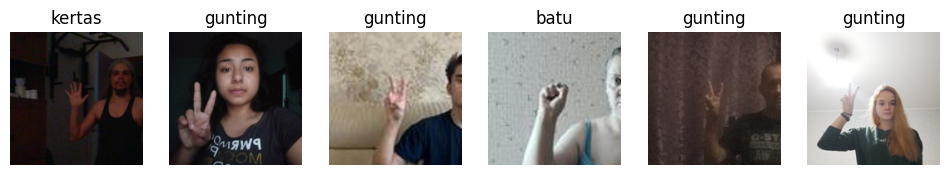

In [7]:
HAGRID_KELAS = {"fist": 0, "palm": 1, "peace": 2}   # 0 batu, 1 kertas, 2 gunting
MAKS_PER_KELAS = 1000

def crop_tangan(img, box):
    # box = [x, y, lebar, tinggi] dalam skala 0-1
    W, H = img.size
    cx, cy = (box[0] + box[2] / 2) * W, (box[1] + box[3] / 2) * H
    sisi = max(box[2] * W, box[3] * H) * np.random.uniform(2, 6)
    kiri, atas = max(0, cx - sisi / 2), max(0, cy - sisi / 2)
    return img.crop((kiri, atas, min(W, kiri + sisi), min(H, atas + sisi)))

Xh, yh = [], []
for kelas, label in HAGRID_KELAS.items():
    folder = [d for d in glob.glob("hagrid/**/", recursive=True)
              if os.path.basename(d.rstrip("/")) in (kelas, f"train_val_{kelas}")]
    files = sorted(glob.glob(os.path.join(folder[0], "*.jpg")))[:MAKS_PER_KELAS] if folder else []
    for f in files:
        img = Image.open(f).convert("RGB")
        info = anotasi.get(os.path.splitext(os.path.basename(f))[0])
        if info is not None and kelas in info["labels"]:
            img = crop_tangan(img, info["bboxes"][info["labels"].index(kelas)])
        img = ImageOps.fit(img, (IMG_SIZE, IMG_SIZE))
        Xh.append(np.array(img) / 255.0)
        yh.append(label)
    print(kelas, "->", len(files), "foto")

if len(Xh) == 0:
    print("folder kelas tidak ketemu, isi folder hagrid:")
    for d in glob.glob("hagrid/*/*")[:20]:
        print(d)
    raise SystemExit
Xh, yh = np.array(Xh, dtype=np.float32), np.array(yh)

idx = np.random.permutation(len(Xh))
n_train, n_val = int(0.70 * len(Xh)), int(0.15 * len(Xh))
Xh_train, yh_train = Xh[idx[:n_train]], yh[idx[:n_train]]
Xh_val, yh_val = Xh[idx[n_train:n_train + n_val]], yh[idx[n_train:n_train + n_val]]
Xh_test, yh_test = Xh[idx[n_train + n_val:]], yh[idx[n_train + n_val:]]
print("hagrid train:", len(Xh_train), " val:", len(Xh_val), " test:", len(Xh_test))

plt.figure(figsize=(12, 2.5))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    plt.imshow(Xh_train[i])
    plt.title(KELAS[yh_train[i]])
    plt.axis("off")
plt.show()

## 3. Data video sendiri

Supaya model kenal foto asli (bukan cuma gambar render 3D), kami merekam video gestur tangan pakai HP,
lalu video dipotong jadi gambar per frame secara otomatis.

Upload 6 video dengan nama persis seperti ini:

| File | Isi |
|---|---|
| train_batu.mp4, train_kertas.mp4, train_gunting.mp4 | sekitar 30 detik per gestur, tangan digerakkan di beberapa background |
| test_batu.mp4, test_kertas.mp4, test_gunting.mp4 | sekitar 10 detik per gestur, direkam di tempat lain yang tidak ada di video train |

Video test sengaja direkam di tempat berbeda supaya pengujiannya jujur.
Bagian ini opsional. Kalau tidak upload apa-apa (klik Cancel), model dilatih dengan dataset RPS dan Kaggle saja.

In [ ]:
import cv2
from google.colab import files

def video_ke_gambar(file_video, folder_tujuan, jumlah):
    # ambil sejumlah frame yang jaraknya merata dari awal sampai akhir video
    os.makedirs(folder_tujuan, exist_ok=True)
    cap = cv2.VideoCapture(file_video)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    for n, idx in enumerate(np.linspace(0, total - 1, jumlah).astype(int)):
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ok, frame = cap.read()
        if ok:
            cv2.imwrite(os.path.join(folder_tujuan, f"{n:03d}.jpg"), frame)
    cap.release()

if not os.path.exists("foto_sendiri"):
    print("Upload 6 video (klik Cancel kalau tidak ada)")
    up = files.upload()
    for nama in up:
        bagian, kelas = os.path.splitext(nama)[0].lower().split("_")   # contoh: train_batu.mp4
        jumlah = 100 if bagian == "train" else 30
        video_ke_gambar(nama, f"foto_sendiri/{bagian}/{kelas}", jumlah)
        print(nama, "->", len(os.listdir(f"foto_sendiri/{bagian}/{kelas}")), "gambar")

Upload 6 video (klik Cancel kalau tidak ada)


In [ ]:
def load_foto(folder):
    X, y = [], []
    for label, kelas in enumerate(KELAS):
        path = os.path.join(folder, kelas)
        if not os.path.exists(path):
            continue
        for f in sorted(os.listdir(path)):
            if not f.lower().endswith((".jpg", ".jpeg", ".png")):
                continue
            img = Image.open(os.path.join(path, f)).convert("RGB")
            img = ImageOps.exif_transpose(img)            # biar foto HP nggak kebalik
            img = ImageOps.fit(img, (IMG_SIZE, IMG_SIZE))  # crop jadi persegi lalu resize
            X.append(np.array(img) / 255.0)
            y.append(label)
    return np.array(X, dtype=np.float32), np.array(y)

ADA_FOTO = os.path.exists("foto_sendiri/train")
if ADA_FOTO:
    Xf_train, yf_train = load_foto("foto_sendiri/train")
    Xf_test, yf_test = load_foto("foto_sendiri/test")
    print("foto sendiri train:", len(Xf_train), " test:", len(Xf_test))
    print("jumlah per kelas (train):", np.bincount(yf_train, minlength=3))
else:
    print("tidak ada video sendiri, lanjut pakai dataset RPS dan Kaggle")

## 4. Preprocessing dan augmentasi

- Gambar RPS dikecilkan dari 300x300 ke 160x160 dan nilai piksel dibagi 255 (jadi 0-1)
- **Ganti background**: piksel background (putih untuk RPS, hijau untuk foto Kaggle) dideteksi,
  lalu diganti pola warna acak. Prinsipnya sama dengan green screen di film.
  Tujuannya supaya model belajar bentuk tangan, bukan belajar warna background.
  Dipakai di 70% gambar train.
- Foto Kaggle juga diputar acak 0/90/180/270 derajat, karena di dataset aslinya tangan selalu datang dari samping.

In [ ]:
BATCH = 32

def preprocess(img, label):
    img = tf.image.resize(img, (IMG_SIZE, IMG_SIZE))
    img = img / 255.0
    return img, label

def background_acak():
    # noise kecil yang diperbesar, hasilnya bercak-bercak warna halus
    bercak = tf.image.resize(tf.random.uniform((6, 6, 3)), (IMG_SIZE, IMG_SIZE))
    warna = tf.random.uniform((1, 1, 3))
    return 0.5 * bercak + 0.5 * warna

def tempel_background(img, mask):
    img_baru = img * (1 - mask) + background_acak() * mask
    return tf.cond(tf.random.uniform(()) < 0.7, lambda: img_baru, lambda: img)

def ganti_bg_putih(img, label):
    # piksel yang semua channel-nya > 0.85 dianggap background putih
    mask = tf.cast(tf.reduce_min(img, axis=-1, keepdims=True) > 0.85, tf.float32)
    return tempel_background(img, mask), label

def ganti_bg_hijau(img, label):
    # piksel yang hijaunya jauh lebih besar dari merah dan biru dianggap background hijau
    r, g, b = img[..., 0], img[..., 1], img[..., 2]
    mask = tf.cast(g - tf.maximum(r, b) > 0.08, tf.float32)[..., tf.newaxis]
    img = tempel_background(img, mask)
    img = tf.image.rot90(img, k=tf.random.uniform((), 0, 4, dtype=tf.int32))
    return img, label

rps_train = train_ds.map(preprocess).map(ganti_bg_putih)
kaggle_train = tf.data.Dataset.from_tensor_slices((Xk_train, yk_train)).map(ganti_bg_hijau)
hagrid_train = tf.data.Dataset.from_tensor_slices((Xh_train, yh_train))   # background asli, tidak diganti
gabungan = rps_train.concatenate(kaggle_train).concatenate(hagrid_train)

if ADA_FOTO:
    # foto sendiri jumlahnya lebih sedikit, jadi diulang 2x biar pengaruhnya terasa
    foto_train = tf.data.Dataset.from_tensor_slices((Xf_train, yf_train)).repeat(2)
    gabungan = gabungan.concatenate(foto_train)

train_ds = gabungan.shuffle(6000).batch(BATCH).prefetch(1)

# validasi gabungan RPS + Kaggle + HaGRID, supaya early stopping juga memperhatikan foto asli
kaggle_val = tf.data.Dataset.from_tensor_slices((Xk_val, yk_val))
hagrid_val = tf.data.Dataset.from_tensor_slices((Xh_val, yh_val))
val_ds = val_ds.map(preprocess).concatenate(kaggle_val).concatenate(hagrid_val).batch(BATCH).prefetch(1)
test_ds = test_ds.map(preprocess).batch(BATCH).prefetch(1)

In [ ]:
# cek hasil ganti background (campuran RPS dan Kaggle)
contoh, lbl = next(iter(train_ds))
plt.figure(figsize=(12, 3))
for i in range(6):
    plt.subplot(1, 6, i + 1)
    plt.imshow(contoh[i])
    plt.title(KELAS[lbl[i]])
    plt.axis("off")
plt.show()

## 5. Model MobileNetV2 (transfer learning)

MobileNetV2 (Sandler dkk., 2018) adalah CNN ringan buatan Google yang dirancang untuk HP.
Kuncinya ada di **depthwise separable convolution**: konvolusi biasa dipecah jadi 2 langkah
(filter per channel, lalu konvolusi 1x1 untuk menggabungkan channel), sehingga hitungannya jauh lebih sedikit.
Blok-bloknya disusun sebagai **inverted residual**: channel diperlebar, difilter, lalu dipersempit lagi,
dengan jalan pintas (skip connection) seperti ResNet.

**Transfer learning**: bagian konvolusi MobileNetV2 memakai bobot yang sudah dilatih di ImageNet
(1,2 juta foto, 1000 kelas), jadi model sudah bisa mengenali tepi, tekstur, bentuk, wajah, dan tangan.
Bagian klasifikasi aslinya (1000 kelas) dibuang dan diganti dengan classifier baru untuk 3 kelas:

| Layer | Keterangan |
|---|---|
| Augmentasi | flip, rotasi, zoom, geser, kecerahan, kontras (hanya saat training) |
| Rescaling | piksel 0-1 diubah ke -1 sampai 1 (format input MobileNetV2) |
| MobileNetV2 | feature extractor, bobot ImageNet, dibekukan |
| GlobalAveragePooling | rata-rata tiap feature map, hasilnya vektor 1280 angka |
| Dropout 0.3 | mengurangi overfitting |
| Dense 3 softmax | output peluang batu, kertas, gunting |

In [ ]:
base = tf.keras.applications.MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                                         include_top=False, weights="imagenet")
base.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.15),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.2, value_range=(0, 1)),
    layers.RandomContrast(0.2),

    layers.Rescaling(2.0, offset=-1.0),
    base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(3, activation="softmax"),
])

model.summary()

## 6. Training

Tahap 1: MobileNetV2 dibekukan, hanya classifier baru yang dilatih (learning rate 1e-3).

Tahap 2 (fine-tuning, hanya kalau ada GPU): 30 layer terakhir MobileNetV2 ikut dilatih dengan
learning rate kecil (1e-5), supaya fiturnya lebih menyesuaikan ke gambar tangan.
Layer BatchNormalization tetap dibekukan supaya statistik ImageNet tidak rusak.

Loss sparse categorical crossentropy, optimizer Adam, early stopping kalau val_loss tidak membaik 3 epoch.

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])

early_stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3,
                                              restore_best_weights=True)

hist1 = model.fit(train_ds, validation_data=val_ds, epochs=10, callbacks=[early_stop])

In [ ]:
ADA_GPU = len(tf.config.list_physical_devices("GPU")) > 0

if ADA_GPU:
    base.trainable = True
    for layer in base.layers[:-30]:
        layer.trainable = False
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    model.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    hist2 = model.fit(train_ds, validation_data=val_ds, epochs=8, callbacks=[early_stop])
else:
    print("Tidak ada GPU, fine-tuning dilewati")
    hist2 = None

In [ ]:
# gabungkan riwayat tahap 1 dan tahap 2
h = {k: list(v) for k, v in hist1.history.items()}
if hist2 is not None:
    for k in h:
        h[k] += hist2.history[k]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(h["accuracy"], label="train")
ax[0].plot(h["val_accuracy"], label="validasi")
ax[0].set_title("Akurasi")
ax[1].plot(h["loss"], label="train")
ax[1].plot(h["val_loss"], label="validasi")
ax[1].set_title("Loss")
for a in ax:
    if hist2 is not None:
        a.axvline(len(hist1.history["loss"]) - 0.5, color="gray", linestyle="--")   # mulai fine-tuning
    a.set_xlabel("epoch")
    a.legend()
plt.show()

## 7. Evaluasi

In [ ]:
def evaluasi(X_or_ds, y_true, judul):
    y_pred = np.argmax(model.predict(X_or_ds, verbose=0), axis=1)
    print(f"=== {judul} ===")
    print(f"Akurasi: {np.mean(y_pred == y_true)*100:.2f}%")
    print(classification_report(y_true, y_pred, target_names=KELAS, digits=4, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=KELAS, yticklabels=KELAS)
    plt.xlabel("Prediksi")
    plt.ylabel("Aktual")
    plt.title(f"Confusion Matrix - {judul}")
    plt.show()

# data test RPS (gambar render 3D)
y_test = np.concatenate([y for _, y in test_ds])
evaluasi(test_ds, y_test, "Test RPS")

In [ ]:
# data test foto asli Kaggle (belum pernah dilihat saat training)
evaluasi(Xk_test, yk_test, "Test foto asli Kaggle")

In [ ]:
# data test HaGRID (foto orang dengan wajah dan ruangan, belum pernah dilihat saat training)
evaluasi(Xh_test, yh_test, "Test HaGRID")

In [ ]:
# data test video sendiri
if ADA_FOTO and len(Xf_test) > 0:
    evaluasi(Xf_test, yf_test, "Test video sendiri")

In [ ]:
# contoh prediksi, judul merah = salah tebak
if ADA_FOTO and len(Xf_test) > 0:
    imgs, labels = Xf_test, yf_test
else:
    imgs, labels = Xh_test, yh_test

pilih = np.random.choice(len(imgs), min(12, len(imgs)), replace=False)
pred = np.argmax(model.predict(imgs[pilih], verbose=0), axis=1)

plt.figure(figsize=(12, 6))
for j, i in enumerate(pilih):
    plt.subplot(2, 6, j + 1)
    plt.imshow(imgs[i])
    warna = "green" if pred[j] == labels[i] else "red"
    plt.title(f"asli: {KELAS[labels[i]]}\nprediksi: {KELAS[pred[j]]}", color=warna, fontsize=9)
    plt.axis("off")
plt.show()

## 8. Apa yang dilihat CNN?

Visualisasi 6 dari 32 filter di layer konvolusi pertama MobileNetV2 (Conv1).
Tiap filter menangkap pola yang berbeda, misalnya tepi jari atau batas tangan dengan background.

In [ ]:
ekstraktor = tf.keras.Model(base.input, base.get_layer("Conv1_relu").output)

img = imgs[pilih[0]]
fmap = ekstraktor(img[np.newaxis] * 2.0 - 1.0)   # input disamakan dengan Rescaling di model

plt.figure(figsize=(14, 3))
plt.subplot(1, 7, 1)
plt.imshow(img)
plt.title("input")
plt.axis("off")
for i in range(6):
    plt.subplot(1, 7, i + 2)
    plt.imshow(fmap[0, :, :, i], cmap="viridis")
    plt.title(f"filter {i+1}")
    plt.axis("off")
plt.show()

In [ ]:
model.save("mobilenetv2_batu_gunting_kertas.keras")

## 9. Coba foto sendiri

In [ ]:
upload = files.upload()

for nama in upload:
    img = Image.open(nama).convert("RGB")
    img = ImageOps.exif_transpose(img)
    img = ImageOps.fit(img, (IMG_SIZE, IMG_SIZE))

    x = np.array(img) / 255.0
    prob = model.predict(x[np.newaxis], verbose=0)[0]

    plt.imshow(img)
    plt.title(f"prediksi: {KELAS[np.argmax(prob)]}")
    plt.axis("off")
    plt.show()

    for k, p in zip(KELAS, prob):
        print(f"{k}: {p*100:.1f}%")